# Experimento de sensibilidade

Execute as células em ordem. O experimento compara políticas em cinco cenários simulados de fadiga e recuperação. Resultados concluídos são retomados automaticamente.


In [1]:
from pathlib import Path
import os
import subprocess
import sys

# Se a busca automatica nao encontrar o projeto, informe abaixo o caminho
# acessivel pelo kernel, por exemplo: ROOT_MANUAL = '/projetos/g8x7/pomodoro-rl'
ROOT_MANUAL = "/projetos/g8x7/pomodoro-rl"
DIRETORIO_ATUAL = Path.cwd().resolve()
candidatos = [Path(ROOT_MANUAL).expanduser()] if ROOT_MANUAL else [DIRETORIO_ATUAL, *DIRETORIO_ATUAL.parents]
ROOT = next((p.resolve() for p in candidatos if (p / 'src' / 'sensibilidade.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        f'Projeto nao encontrado a partir de {DIRETORIO_ATUAL}. '
        'Defina ROOT_MANUAL nesta celula com o caminho da pasta pomodoro-rl acessivel pelo kernel.'
    )
print(f'Pasta do projeto: {ROOT}')

N_CPUS = 28
RAPIDO = False  # False para executar o experimento completo
CPUS_USADAS = max(1, min(N_CPUS, os.cpu_count() or 1))
PASTA = ROOT / 'experiments' / ('sensibilidade_rapida' if RAPIDO else 'sensibilidade')
comando = [sys.executable, str(ROOT / 'src' / 'sensibilidade.py'), '--cpus', str(CPUS_USADAS)]
if RAPIDO:
    comando.append('--rapido')
print(f'CPUs solicitadas: {N_CPUS} | usando: {CPUS_USADAS} | rápido: {RAPIDO}')
print(f'Resultados: {PASTA}')


Pasta do projeto: /projetos/g8x7/pomodoro-rl
CPUs solicitadas: 28 | usando: 28 | rápido: False
Resultados: /projetos/g8x7/pomodoro-rl/experiments/sensibilidade


## Sensibilidade com 30 sementes
As sete políticas usam as mesmas sementes nos cinco cenários. A grade retoma as execuções concluídas da pasta selecionada.

In [7]:
sys.path.insert(0, str(ROOT/'src'))
import json
import numpy as np
import pandas as pd
from sensibilidade import CENARIOS, resultados
from executar_grade import jobs_grade
from paralelo import run_jobs
from agentes import TODOS, APRENDEM, criar_agente
from simulador import SimuladorPomodoro
from treino import avaliar

sementes = list(range(11, 331, 11))
jobs = []
for cenario, ajustes in CENARIOS.items():
    pendentes, _ = jobs_grade(ROOT/'config/padrao.json', PASTA/cenario,
        variantes=['eficaz'], penalidades=[10], sementes=sementes, sets=ajustes, rapido=RAPIDO)
    jobs.extend(pendentes)
print(len(jobs), 'execuções pendentes')
run_jobs(jobs, workers=CPUS_USADAS, desc='Sensibilidade')
resultados(PASTA)
dados = pd.read_csv(PASTA/'execucoes.csv')
dados = dados[dados.semente.isin(sementes) & dados.cenario.isin(CENARIOS) & dados.algoritmo.isin(TODOS)].copy()
chaves = ['cenario', 'algoritmo', 'semente']
assert len(dados) == len(CENARIOS)*len(TODOS)*30 and not dados.duplicated(chaves).any()
dados['cansaco_pct'] = 100*dados.fracao_cansaco_alto

0 execuções pendentes
Nada a executar: todas as execuções já estão concluídas.


## Médias e diferenças pareadas
IC de 95% pontual pela distribuição t de Student com 29 graus de liberdade. Cada observação representa uma semente. Rendimento em minutos efetivos por hora e cansaço em porcentagem dos ciclos. Para diferenças, cansaço é expresso em pontos percentuais. Valores positivos indicam que Q-learning teve valor maior na métrica.

In [3]:
metricas = ['efetivos_por_hora', 'cansaco_pct']
def resumo(df, grupos):
    longo = df.melt(id_vars=grupos + ['semente'], value_vars=metricas, var_name='metrica')
    tab = longo.groupby(grupos + ['metrica']).value.agg(['mean','sem','count'])
    assert tab['count'].eq(30).all()
    margem = 2.045229642 * tab['sem']
    return tab.assign(ic_inf=tab['mean']-margem, ic_sup=tab['mean']+margem).drop(columns='sem')

def pareadas(df):
    largo = df.set_index(chaves).sort_index()[metricas]
    q = largo.xs('qlearning', level='algoritmo')
    partes = []
    for outro in ['bandit','fixo_curto']:
        delta = q - largo.xs(outro, level='algoritmo')
        partes.append(delta.reset_index().assign(comparacao='Q-learning menos ' + outro))
    return resumo(pd.concat(partes), ['cenario','comparacao'])

display(resumo(dados, ['cenario','algoritmo']).round(3))
display(pareadas(dados).round(3))

mean  count  ic_inf  ic_sup
cenario      algoritmo   metrica                                         
fadiga_lenta aleatorio   cansaco_pct         5.510     30   5.426   5.594
                         efetivos_por_hora  36.312     30  36.264  36.361
             bandit      cansaco_pct        24.619     30  22.081  27.157
                         efetivos_por_hora  24.997     30  24.198  25.796
             fixo_curto  cansaco_pct         0.000     30   0.000   0.000
...                                            ...    ...     ...     ...
referencia   fixo_padrao efetivos_por_hora  31.514     30  31.467  31.560
             qlearning   cansaco_pct         5.728     30   3.454   8.002
                         efetivos_por_hora  34.631     30  33.527  35.736
             regra       cansaco_pct        43.028     30  42.924  43.131
                         efetivos_por_hora  24.163     30  24.141  24.185

[70 rows x 4 columns]

mean  \
cenario            comparacao                  metrica                     
fadiga_lenta       Q-learning menos bandit     cansaco_pct       -22.775   
                                               efetivos_por_hora  11.470   
                   Q-learning menos fixo_curto cansaco_pct         1.844   
                                               efetivos_por_hora  -7.230   
fadiga_rapida      Q-learning menos bandit     cansaco_pct       -44.630   
                                               efetivos_por_hora  21.163   
                   Q-learning menos fixo_curto cansaco_pct         3.268   
                                               efetivos_por_hora  -6.110   
recuperacao_lenta  Q-learning menos bandit     cansaco_pct       -64.694   
                                               efetivos_por_hora  21.592   
                   Q-learning menos fixo_curto cansaco_pct         5.582   
                                               efetivos_por_hora  -6.253   
recuperacao_rapida Q-learning menos bandit     cansaco_pct       -17.989   
                                               efetivos_por_hora  18.471   
                   Q-learning menos fixo_curto cansaco_pct         1.113   
                                               efetivos_por_hora  -6.962   
referencia         Q-learning menos bandit     cansaco_pct       -27.279   
                                               efetivos_por_hora  14.044   
                   Q-learning menos fixo_curto cansaco_pct         5.728   
                                               efetivos_por_hora  -8.347   

                                                                  count  \
cenario            comparacao                  metrica                    
fadiga_lenta       Q-learning menos bandit     cansaco_pct           30   
                                               efetivos_por_hora     30   
                   Q-learning menos fixo_curto cansaco_pct           30   
                                               efetivos_por_hora     30   
fadiga_rapida      Q-learning menos bandit     cansaco_pct           30   
                                               efetivos_por_hora     30   
                   Q-learning menos fixo_curto cansaco_pct           30   
                                               efetivos_por_hora     30   
recuperacao_lenta  Q-learning menos bandit     cansaco_pct           30   
                                               efetivos_por_hora     30   
                   Q-learning menos fixo_curto cansaco_pct           30   
                                               efetivos_por_hora     30   
recuperacao_rapida Q-learning menos bandit     cansaco_pct           30   
                                               efetivos_por_hora     30   
                   Q-learning menos fixo_curto cansaco_pct           30   
                                               efetivos_por_hora     30   
referencia         Q-learning menos bandit     cansaco_pct           30   
                                               efetivos_por_hora     30   
                   Q-learning menos fixo_curto cansaco_pct           30   
                                               efetivos_por_hora     30   

                                                                  ic_inf  \
cenario            comparacao                  metrica                     
fadiga_lenta       Q-learning menos bandit     cansaco_pct       -25.465   
                                               efetivos_por_hora  10.148   
                   Q-learning menos fixo_curto cansaco_pct         1.144   
                                               efetivos_por_hora  -8.227   
fadiga_rapida      Q-learning menos bandit     cansaco_pct       -48.210   
                                               efetivos_por_hora  19.655   
                   Q-learning menos fixo_curto cansaco_pct         1.588   
                                               efetivos_por_

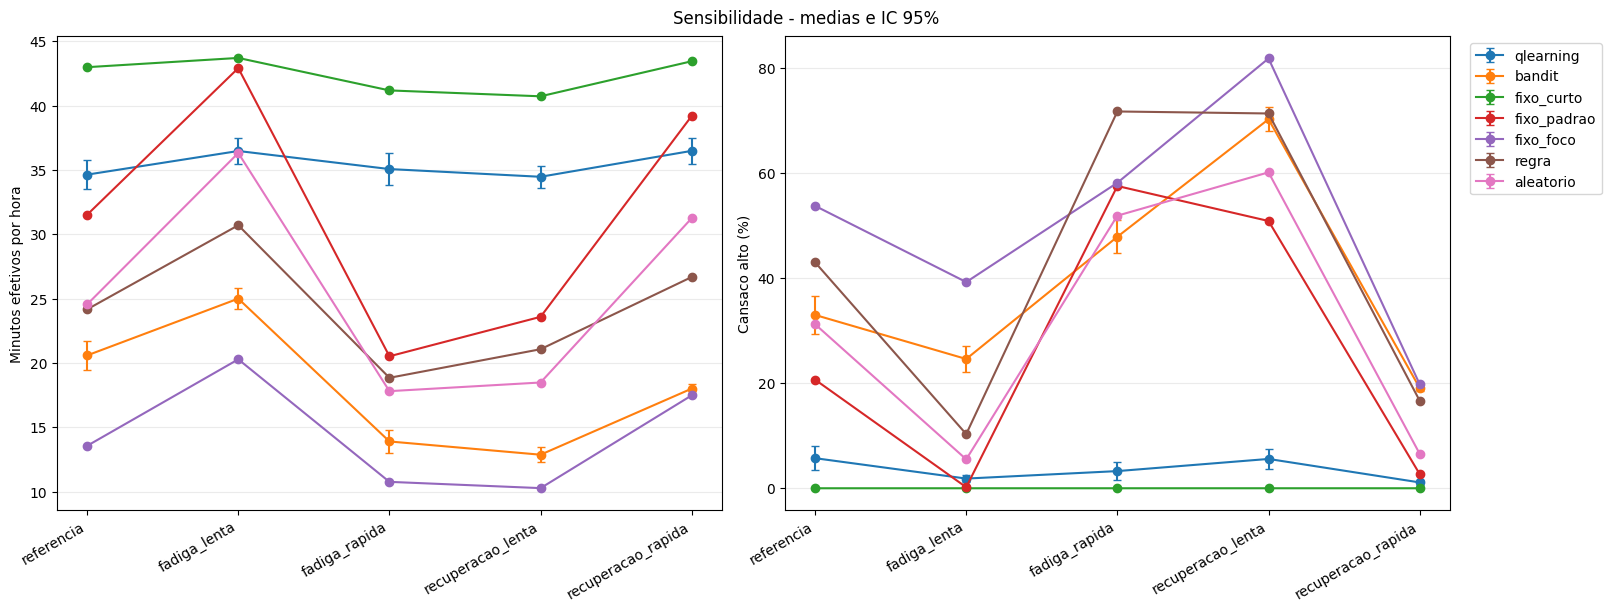

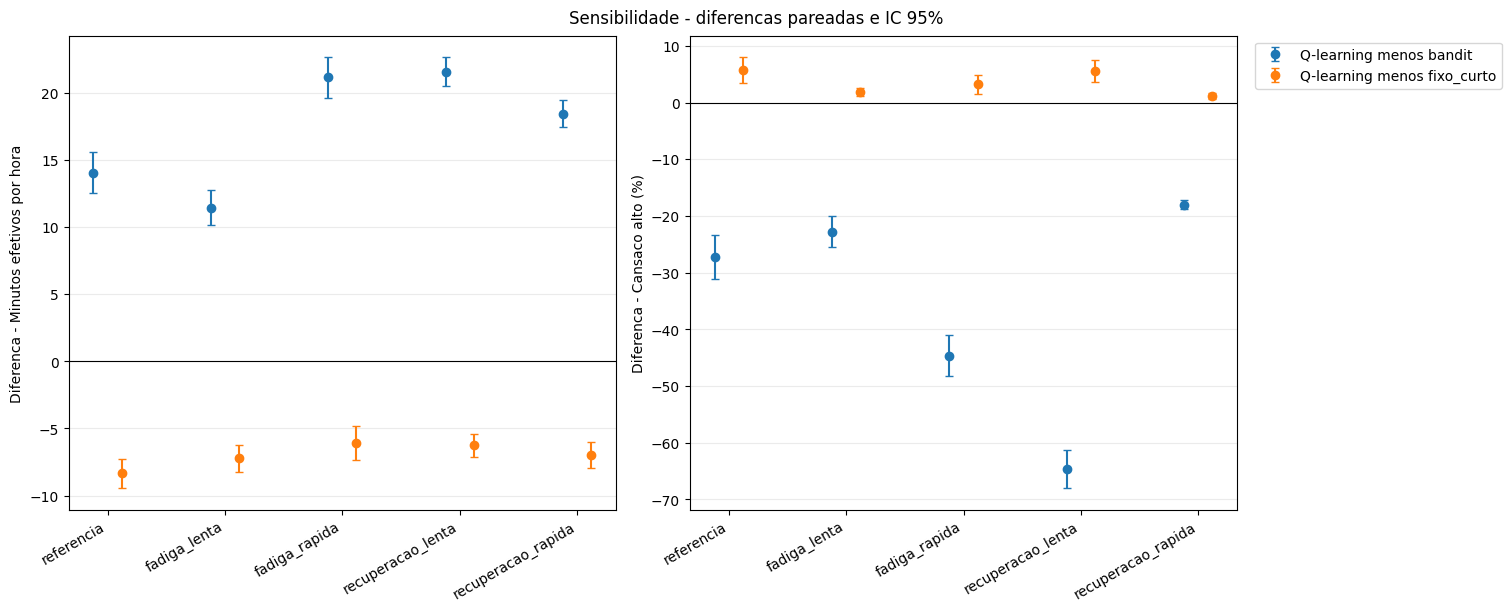

In [9]:
import matplotlib.pyplot as plt

def mostrar_graficos(df, titulo):
    cenarios = list(CENARIOS)
    medias = resumo(df, ['cenario', 'algoritmo']).reset_index()
    diferencas = pareadas(df).reset_index()
    nomes = {'efetivos_por_hora': 'Minutos efetivos por hora', 'cansaco_pct': 'Cansaco alto (%)'}

    fig, eixos = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
    for eixo, metrica in zip(eixos, metricas):
        for algoritmo in TODOS:
            serie = medias[(medias.metrica == metrica) & (medias.algoritmo == algoritmo)].set_index('cenario').loc[cenarios]
            eixo.errorbar(range(len(cenarios)), serie['mean'],
                yerr=[serie['mean'] - serie['ic_inf'], serie['ic_sup'] - serie['mean']],
                marker='o', capsize=3, label=algoritmo)
        eixo.set_xticks(range(len(cenarios)), cenarios, rotation=30, ha='right')
        eixo.set_ylabel(nomes[metrica])
        eixo.grid(axis='y', alpha=0.25)
    eixos[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    fig.suptitle(titulo + ' - medias e IC 95%')
    plt.show()

    fig, eixos = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
    for eixo, metrica in zip(eixos, metricas):
        for deslocamento, comparacao in [(-0.12, 'Q-learning menos bandit'), (0.12, 'Q-learning menos fixo_curto')]:
            serie = diferencas[(diferencas.metrica == metrica) & (diferencas.comparacao == comparacao)].set_index('cenario').loc[cenarios]
            eixo.errorbar(np.arange(len(cenarios)) + deslocamento, serie['mean'],
                yerr=[serie['mean'] - serie['ic_inf'], serie['ic_sup'] - serie['mean']],
                marker='o', capsize=3, linestyle='none', label=comparacao)
        eixo.axhline(0, color='black', linewidth=0.8)
        eixo.set_xticks(range(len(cenarios)), cenarios, rotation=30, ha='right')
        eixo.set_ylabel('Diferenca - ' + nomes[metrica])
        eixo.grid(axis='y', alpha=0.25)
    eixos[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    fig.suptitle(titulo + ' - diferencas pareadas e IC 95%')
    plt.show()

mostrar_graficos(dados, 'Sensibilidade')


## Generalização a partir da referência
Para cada semente, recuperamos as tabelas Q treinadas na referência e as avaliamos sem atualização nos cinco ambientes. Todas as políticas recebem a mesma semente de ambiente por comparação. As políticas fixas, a regra e a aleatória também são avaliadas nesse protocolo.

In [5]:
registros = {}
for arquivo in PASTA.glob('*/*/concluido.json'):
    r = json.loads(arquivo.read_text(encoding='utf8'))
    registros[arquivo.parents[1].name, r['algoritmo'], r['semente']] = r

from tqdm.auto import tqdm

linhas = []
progresso = tqdm(total=len(CENARIOS) * len(sementes) * len(TODOS), desc='Generalizacao', unit='avaliacao')
for cenario in CENARIOS:
    for semente in sementes:
        for algoritmo in TODOS:
            cfg = registros[cenario, algoritmo, semente]['config']
            agente = criar_agente(algoritmo, cfg, np.random.default_rng([semente, 4]))
            if algoritmo in APRENDEM:
                agente.Q[:] = registros['referencia', algoritmo, semente]['Q']
            env = SimuladorPomodoro(cfg, np.random.default_rng([semente, 3]))
            m = avaliar(cfg, agente, env, lambda _: None)
            sim = cfg['simulador']
            duracao = sum(f*sum(sim['ciclos'][a]) for a,f in m['uso_acoes'].items())
            tempo = sim['n_ciclos_por_episodio'] * duracao
            linhas.append(dict(cenario=cenario, algoritmo=algoritmo, semente=semente,
                efetivos_por_hora=60*m['minutos_efetivos_por_episodio']/tempo,
                cansaco_pct=100*m['freq_cansaco_alto']))
            progresso.update(1)
progresso.close()
generalizacao = pd.DataFrame(linhas)
display(resumo(generalizacao, ['cenario','algoritmo']).round(3))
display(pareadas(generalizacao).round(3))

Generalizacao:   0%|          | 0/1050 [00:00<?, ?avaliacao/s]

mean  count  ic_inf  ic_sup
cenario      algoritmo   metrica                                         
fadiga_lenta aleatorio   cansaco_pct         5.613     30   5.524   5.703
                         efetivos_por_hora  36.254     30  36.202  36.306
             bandit      cansaco_pct        14.755     30  11.569  17.941
                         efetivos_por_hora  28.154     30  27.084  29.224
             fixo_curto  cansaco_pct         0.000     30   0.000   0.000
...                                            ...    ...     ...     ...
referencia   fixo_padrao efetivos_por_hora  31.460     30  31.402  31.517
             qlearning   cansaco_pct         5.716     30   3.419   8.013
                         efetivos_por_hora  34.642     30  33.521  35.762
             regra       cansaco_pct        43.048     30  42.903  43.194
                         efetivos_por_hora  24.145     30  24.115  24.176

[70 rows x 4 columns]

mean  \
cenario            comparacao                  metrica                     
fadiga_lenta       Q-learning menos bandit     cansaco_pct       -14.005   
                                               efetivos_por_hora  11.994   
                   Q-learning menos fixo_curto cansaco_pct         0.750   
                                               efetivos_por_hora  -3.542   
fadiga_rapida      Q-learning menos bandit     cansaco_pct       -30.336   
                                               efetivos_por_hora  12.751   
                   Q-learning menos fixo_curto cansaco_pct        17.177   
                                               efetivos_por_hora -12.055   
recuperacao_lenta  Q-learning menos bandit     cansaco_pct       -46.072   
                                               efetivos_por_hora  14.300   
                   Q-learning menos fixo_curto cansaco_pct        16.762   
                                               efetivos_por_hora -10.074   
recuperacao_rapida Q-learning menos bandit     cansaco_pct        -9.462   
                                               efetivos_por_hora  13.307   
                   Q-learning menos fixo_curto cansaco_pct         1.326   
                                               efetivos_por_hora  -5.965   
referencia         Q-learning menos bandit     cansaco_pct       -27.475   
                                               efetivos_por_hora  14.093   
                   Q-learning menos fixo_curto cansaco_pct         5.716   
                                               efetivos_por_hora  -8.324   

                                                                  count  \
cenario            comparacao                  metrica                    
fadiga_lenta       Q-learning menos bandit     cansaco_pct           30   
                                               efetivos_por_hora     30   
                   Q-learning menos fixo_curto cansaco_pct           30   
                                               efetivos_por_hora     30   
fadiga_rapida      Q-learning menos bandit     cansaco_pct           30   
                                               efetivos_por_hora     30   
                   Q-learning menos fixo_curto cansaco_pct           30   
                                               efetivos_por_hora     30   
recuperacao_lenta  Q-learning menos bandit     cansaco_pct           30   
                                               efetivos_por_hora     30   
                   Q-learning menos fixo_curto cansaco_pct           30   
                                               efetivos_por_hora     30   
recuperacao_rapida Q-learning menos bandit     cansaco_pct           30   
                                               efetivos_por_hora     30   
                   Q-learning menos fixo_curto cansaco_pct           30   
                                               efetivos_por_hora     30   
referencia         Q-learning menos bandit     cansaco_pct           30   
                                               efetivos_por_hora     30   
                   Q-learning menos fixo_curto cansaco_pct           30   
                                               efetivos_por_hora     30   

                                                                  ic_inf  \
cenario            comparacao                  metrica                     
fadiga_lenta       Q-learning menos bandit     cansaco_pct       -17.223   
                                               efetivos_por_hora  10.566   
                   Q-learning menos fixo_curto cansaco_pct         0.266   
                                               efetivos_por_hora  -4.428   
fadiga_rapida      Q-learning menos bandit     cansaco_pct       -35.040   
                                               efetivos_por_hora  11.195   
                   Q-learning menos fixo_curto cansaco_pct        12.887   
                                               efetivos_por_

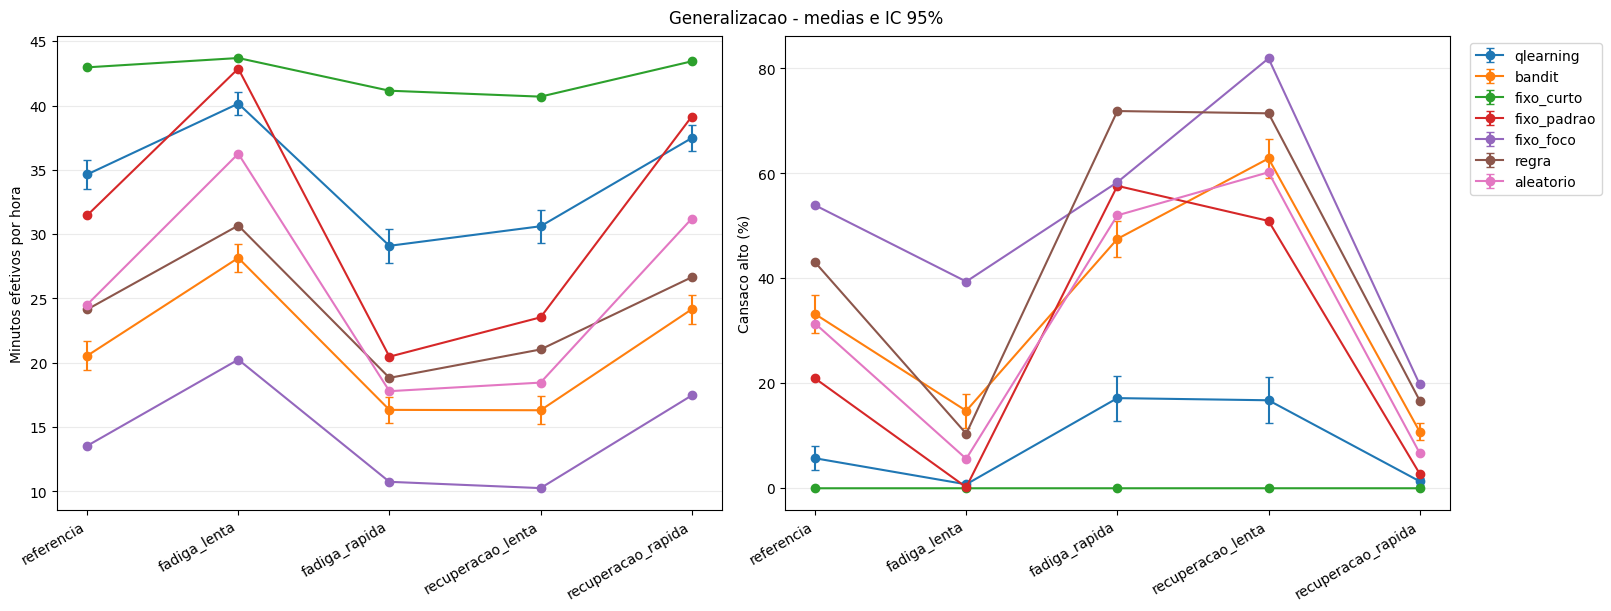

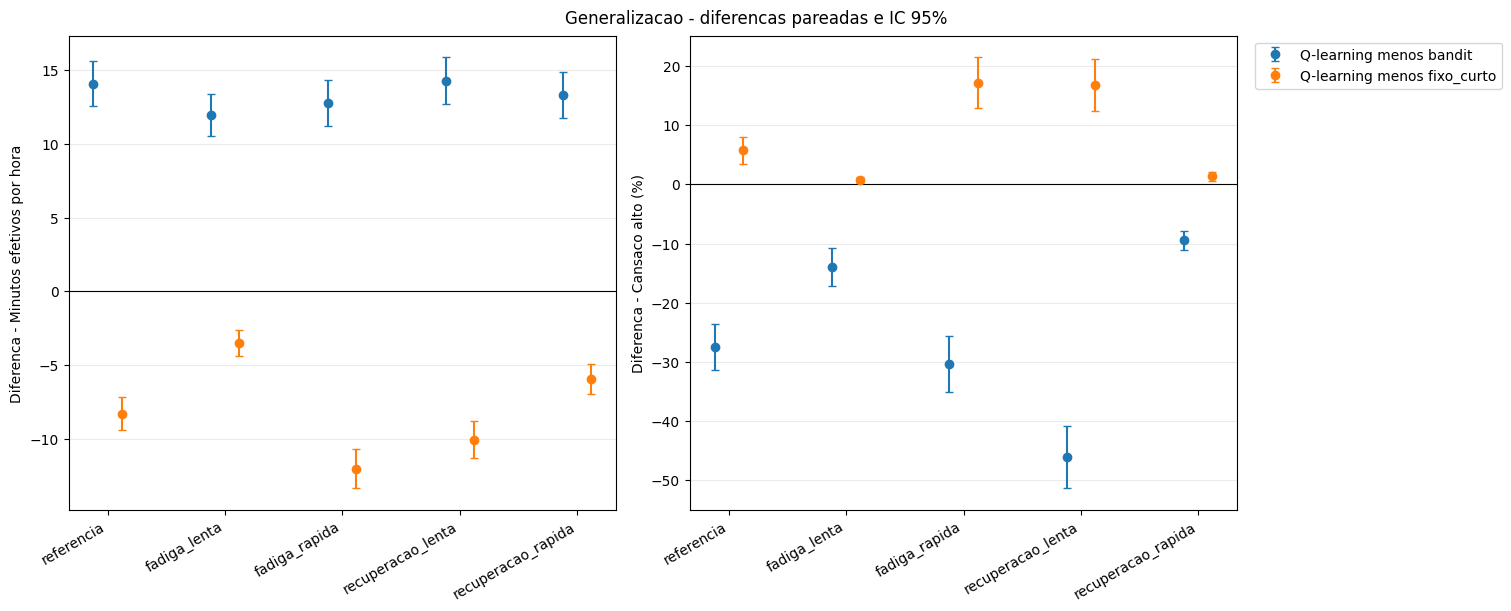

In [10]:
mostrar_graficos(generalizacao, 'Generalizacao')
